# Predict Movie Genre and Rating in Test/Train Data

Using the k-nearest neighbors method, use the top-k most similar movies to a target film to predict the target movie's genre and rating.

Use Jaccard similarity based on actors in each movie to rank movies and select the top-k most similar movies.

In [30]:
import json

import pandas as pd
import numpy as np

from scipy.sparse import lil_matrix

import matplotlib.pyplot as plt

from tqdm.notebook import tqdm
from scipy.sparse import lil_matrix

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier

In [31]:
actor_name_map = {}
movie_actor_map = {}
actor_genre_map = {}


with open("imdb_movies_2000to2022.prolific.json", "r") as in_file:
    for line in in_file:
        
        # Read the movie on this line and parse its json
        this_movie = json.loads(line)
        
        # Skip movies with no ratings
        if len(this_movie["rating"]) == 0:
            continue
                    
        # Add all actors to the id->name map
        for actor_id,actor_name in this_movie['actors']:
            actor_name_map[actor_id] = actor_name
            
        # For each actor, add this movie's genres to that actor's list
        for actor_id,actor_name in this_movie['actors']:
            this_actors_genres = actor_genre_map.get(actor_id, {})
            
            # Increment the count of genres for this actor
            for g in this_movie["genres"]:
                this_actors_genres[g] = this_actors_genres.get(g, 0) + 1
                
            # Update the map
            actor_genre_map[actor_id] = this_actors_genres
            
        # Finished with this film
        movie_actor_map[this_movie["imdb_id"]] = ({
            "movie": this_movie["title"],
            "actors": set([item[0] for item in this_movie['actors']]),
            "genres": this_movie["genres"],
            "rating": this_movie["rating"]["avg"]
        })

In [32]:
print("Known Actors:", len(actor_name_map))
print("Known Movies:", len(movie_actor_map))

Known Actors: 29499
Known Movies: 18841


In [33]:
actor_id_to_index = {actor_id:i for i,actor_id in enumerate(actor_name_map.keys())}
actor_id_to_index

{'nm0000212': 0,
 'nm0413168': 1,
 'nm0000630': 2,
 'nm0005227': 3,
 'nm0864851': 4,
 'nm0828288': 5,
 'nm0933983': 6,
 'nm0329491': 7,
 'nm0000417': 8,
 'nm0000603': 9,
 'nm0000457': 10,
 'nm0452288': 11,
 'nm0001002': 12,
 'nm0001299': 13,
 'nm0923529': 14,
 'nm0936365': 15,
 'nm0006763': 16,
 'nm0007113': 17,
 'nm0310173': 18,
 'nm0412917': 19,
 'nm1142237': 20,
 'nm0321320': 21,
 'nm0001123': 22,
 'nm0898634': 23,
 'nm0269451': 24,
 'nm0803374': 25,
 'nm1315804': 26,
 'nm0803138': 27,
 'nm0001324': 28,
 'nm0920148': 29,
 'nm0115304': 30,
 'nm0203349': 31,
 'nm0427470': 32,
 'nm0001293': 33,
 'nm0001062': 34,
 'nm0732133': 35,
 'nm0000199': 36,
 'nm0001583': 37,
 'nm0283299': 38,
 'nm0568375': 39,
 'nm0000849': 40,
 'nm0603090': 41,
 'nm0098709': 42,
 'nm0617799': 43,
 'nm0089231': 44,
 'nm0175305': 45,
 'nm0001497': 46,
 'nm0000138': 47,
 'nm0000639': 48,
 'nm0641168': 49,
 'nm0377888': 50,
 'nm0290969': 51,
 'nm0000461': 52,
 'nm0001781': 53,
 'nm0002150': 54,
 'nm0463233': 55,
 '

## Split Data into Training/Testing Data

In [34]:
from sklearn.model_selection import train_test_split

In [50]:
all_movie_ids = np.array(list(movie_actor_map.keys()))
training_ids, testing_ids = train_test_split(all_movie_ids, test_size=0.2, random_state =31337)

In [51]:
training_ids.shape, testing_ids.shape

((15072,), (3769,))

In [52]:
def build_matrix(movie_ids):
    matrix_sparse = lil_matrix((len(movie_ids), len(actor_id_to_index)), dtype = bool)

    for row, movie_id in enumerate(movie_ids):
        for actor_id in movie_actor_map[movie_id]["actors"]:
            matrix_sparse[row, actor_id_to_index[actor_id]] = 1

    return matrix_sparse.tocsr()

In [53]:
train_rows = [(movie_id, genre) for movie_id in training_ids for genre in movie_actor_map[movie_id]["genres"]]

x_train = build_matrix([movie_ids for movie_ids, _ in train_rows])
y_train = [genre for _, genre in train_rows]

In [54]:
x_train_films = build_matrix(training_ids)
x_test = build_matrix(testing_ids)
y_test = [movie_actor_map[movie_id]["genres"] for movie_id in testing_ids]

print(x_train.shape, x_test.shape)

(32021, 29499) (3769, 29499)


In [55]:
def genre_accuracy(model, X, movie_ids):
    predicted_genres = model.predict(X)

    correct_genres = [
        1 if predicted_genre in movie_actor_map[movie_id]["genres"] else 0
        for predicted_genre, movie_id in zip(predicted_genres, movie_ids)
    ]

    return sum(correct_genres) / len(correct_genres)

In [56]:
tree_rows = []

for depth in tqdm(range(1,11)):
    model = DecisionTreeClassifier(max_depth=depth, random_state = 31337)
    model.fit(x_train, y_train)

    train_acc = genre_accuracy(model, x_train_films, training_ids)
    test_acc = genre_accuracy(model, x_test, testing_ids)

    tree_rows.append({
        "depth": depth,
        "train_acc": train_acc,
        "test_acc": test_acc
    })

  0%|          | 0/10 [00:00<?, ?it/s]

In [58]:
tree_df = pd.DataFrame(tree_rows)
tree_df

,depth,train_acc,test_acc
0,1,0.506834,0.526400
1,2,0.508493,0.527196
2,3,0.509952,0.527461
3,4,0.511744,0.528257
4,5,0.513601,0.529318
5,6,0.515525,0.530910
6,7,0.516852,0.531441
7,8,0.517848,0.532502
8,9,0.519440,0.533829
9,10,0.520502,0.534359


<Axes: xlabel='Max Depth', ylabel='Accuracy'>

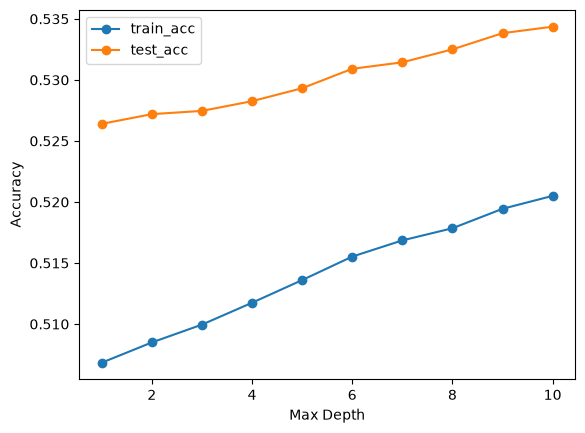

In [59]:
tree_df.plot(x="depth", y=["train_acc", "test_acc"], marker="o", ylabel="Accuracy", xlabel="Max Depth")

## For Each Movie in Test Set, Use Jaccard Similarity by Actor to Predict Genre and Rating

For each movie in the test set, we find the k most similar movies **in the training set** to predict the test movie's genre and its rating.

Then compare the predictions to the actual data from the `movie_actor_map` to calculate accuracy of this prediction.

In [ ]:
k_nn = 10

In [ ]:
prediction_rows = []

for test_movie_id in testing_ids:

    # This test movie
    target_movie_object = movie_actor_map[test_movie_id]
    
    # List of similar movies
    test_movie_similarities = []

    # Iterate through every movie in the training set
    for this_movie_id in training_ids:
        # TODO iterate through all the training movies to find the top-k
        # most similar to this test movie
        # Add result to an array of movies

    
    similarity_df = pd.DataFrame(test_movie_similarities, columns=["movie", "jaccard"])
    
    # Get the top k movies
    top_movies = similarity_df.sort_values(by="jaccard", ascending=False).head(k_nn)

    # iterate through the top k movies and predict genre and rating
    relevant_ratings = []
    relevant_genre_count = {}
    for this_movie_id in top_movies["movie"]:
        # add relevant ratings
        # TODO add relevant rating to `relevant_ratings`
        
        # Track genres
        # TODO add this similar movie's genre to map of genre counts
            
    # Get the most common genre from the neighbors
    predicted_genre = # TODO
    
    # Take the average rating of k neighbors for prediction
    predicted_rating = # TODO
    
    # Track predictions
    prediction_rows.append({
        "imdb_id": test_movie_id,
        "genre": predicted_genre,
        "rating": predicted_rating,
    })


In [ ]:
predicted_df = pd.DataFrame(prediction_rows).set_index("imdb_id")
predicted_df

## Measure Accuracy of Predictions

In [ ]:
correct_genres = []

for movie_id,row in predicted_df.iterrows():

    # TODO calculate accuracy for this movie
    # add 1 to `correct_genres` if predicted genre 
    #. is in the set of actual genres
    
accuracy = sum(correct_genres) / len(correct_genres)
print("Genre Accuracy:", accuracy)

In [ ]:
rating_mses = []

for movie_id,row in predicted_df.iterrows():

    # TODO calculate MSE by squaring the error
    # between predicted and actual rating
    
mse = sum(rating_mses) / len(rating_mses)
print("Rating Mean Squared Error:", mse)